# Proyecto Integrador · Entrega 2: Análisis Exploratorio e Hipótesis
**Ciencia de Datos · UTN FRM · 2026**

- **Grupo**: `5K09-06`
- **Integrantes**:
  - Canzio, Ignacio
  - Fernández Rossi, Matías Tomás
  - García Nieto, Roberto
  - Giacomelli, Luciano
  - Moyano, Gonzalo
  - Rubiales, Fernando
- **Dominio**: Mercado de Alquileres Temporarios en Airbnb (Ciudad Autónoma de Buenos Aires - CABA)
- **Dataset**: `snapshot=2026-07-24.csv` (Capa Silver, output del pipeline ETL en Apache Airflow)
- **Pregunta del Proyecto**: *¿A qué precio debería publicarse un alquiler temporario en CABA, según las características de la propiedad y su ubicación?*

---
### Estructura de la Entrega
1. **Perfil del Dataset (Auditoría Cuantitativa con números a mano)**: Dimensiones, tipos, nulos estructurales, duplicados de clave, distribución y asimetría de la variable objetivo (`price`).
2. **Cuatro Fichas de Hipótesis Metodológicas**:
   - **H1 (Modelado · Asociación · Confirmada tras doble movimiento)**: Capacidad de huéspedes (`accommodates`) vs precio (`price` lineal $\to$ `log_price` $\to$ poda de *outliers* $P_1-P_{99}$, $r = 0.514$).
   - **H2 (Dominio · Comparación · REFUTADA)**: El mito del sobreprecio de los Superhosts (`host_is_superhost` vs `log_price`, $d_{\text{intra}} = 0.174$ Rojo).
   - **H3 (Modelado · Comparación · VERDE)**: Departamento entero (`Entire home/apt`) vs Habitación privada (`Private room`, $d = 1.163$ Verde).
   - **H4 (Dominio · Comparación estratificada · Confirmada tras doble movimiento)**: Sobreprecio de la pileta (`has_pool`) controlando por barrio (`neighbourhood_cleansed`) y tamaño (`accommodates == 2`, $d_{\text{intra}} = 0.432$).
3. **Matriz de Correlación y Tabla de Columnas Candidatas**: Selección de *features* con control estricto de colinealidad y fuga de información (*data leakage*).

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de gráficos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Carga del dataset silver particionado por snapshot
DATASET_PATH = "/content/snapshot=2026-06-29.csv"

df = pd.read_csv(DATASET_PATH, low_memory=False)
print(f"Dataset silver cargado con éxito: {df.shape[0]:,} publicaciones x {df.shape[1]} columnas.")

Dataset silver cargado con éxito: 27,893 publicaciones x 31 columnas.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def separacion(x, y):
    """Distancia entre dos muestras independientes, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

def eta2(numerica, categoria):
    """Proporción de varianza de la variable numérica explicada por la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

def asociacion(x, y):
    """Coeficiente de correlación de Pearson, Spearman y brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

# Cortes normativos del semáforo metodológico de la cátedra
CORTES = {
    "separacion": (0.2, 0.8),
    "eta2": (0.05, 0.25),
    "correlacion": (0.2, 0.6),
    "brecha": (0.05, 0.15)
}

def semaforo(valor, medida):
    """Devuelve la zona del semáforo (rojo, amarillo o verde) según los cortes metodológicos."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


# Sección 1: El Perfil del Dataset

En esta sección se auditan los siete indicadores numéricos obligatorios requeridos por la cátedra para verificar la integridad del dataset antes de plantear modelos:
1. **Tamaño**: Cantidad de filas y columnas, y definición semántica de una fila.
2. **Tipos de datos**: Conteo por tipo y validación de tipos numéricos.
3. **Nulos por columna**: Análisis causal de las tres variables con mayor cantidad de faltantes.
4. **Columnas sin información**: Detección de constantes o columnas completamente vacías.
5. **Duplicados de la clave**: Verificación de unicidad de la clave primaria `id`.
6. **Distribución del objetivo (`price`)**: Asimetría lineal y justificación de la transformación logarítmica.
7. **Asimetría de variables numéricas**: Diagnóstico de colas largas que requieren transformación.


In [ ]:
# 1. Tamaño y definición de la unidad de análisis
filas, columnas = df.shape
print(f"1. Tamaño: {filas:,} filas y {columnas} columnas.")
print("   Unidad de análisis: Cada fila representa una publicación activa de alquiler temporario en CABA.")

# 2. Conteo por tipos de datos
print("\n2. Tipos de datos en el DataFrame:")
print(df.dtypes.value_counts())

# 3. Nulos por columna y porcentaje
nulos_serie = df.isna().mean().sort_values(ascending=False)
nulos_df = pd.DataFrame({
    "Faltantes absolutos": df.isna().sum()[nulos_serie > 0],
    "Porcentaje (%)": (nulos_serie[nulos_serie > 0] * 100).round(2)
})
print("\n3. Columnas con valores nulos:")
print(nulos_df)

# 4. Columnas sin información (constantes o 100% nulas)
constantes = df.columns[df.nunique(dropna=False) <= 1].tolist()
print(f"\n4. Columnas sin información (nunique <= 1): {constantes} (0 columnas constantes)")

# 5. Duplicados de la clave primaria
dups_id = df["id"].duplicated().sum()
print(f"\n5. Duplicados de la clave primaria 'id': {dups_id} (Garantiza clave única)")


1. Tamaño: 27,893 filas y 31 columnas.
   Unidad de análisis: Cada fila representa una publicación activa de alquiler temporario en CABA.

2. Tipos de datos en el DataFrame:
bool       10
float64     8
int64       7
object      6
Name: count, dtype: int64

3. Columnas con valores nulos:
                      Faltantes absolutos  Porcentaje (%)
bathrooms                              83            0.30
bathrooms_shared                       24            0.09
bedrooms                             4915           17.62
beds                                 1256            4.50
minimum_nights                          3            0.01
review_scores_rating                 3366           12.07

4. Columnas sin información (nunique <= 1): [] (0 columnas constantes)

5. Duplicados de la clave primaria 'id': 0 (Garantiza clave única)


### Análisis Causal de los Valores Faltantes
De acuerdo al análisis, se logro distinguir los **faltantes reales de nulos estructurales**:
1. **`bedrooms` ($17.62\%$ nulos, $4.915$ filas)**: Es un **nulo estructural legítimo**. En el mercado inmobiliario de CABA, una proporción masiva de las publicaciones son departamentos **monoambientes o estudios (*studio apartments*)**, que no disponen de una habitación físicamente separada del living/comedor. En la etapa de modelado, imputar la media sería un error garrafal; el tratamiento correcto es imputar con $0$ dormitorios e incorporar un indicador de monoambiente.
2. **`review_scores_rating` ($12.07\%$ nulos, $3.366$ filas)**: Es un **faltante por ciclo de vida**. Corresponde exactamente a publicaciones nuevas o recientemente dadas de alta que aún no han recibido reservas puntuadas (`number_of_reviews == 0`). Esta variable además presenta riesgo de fuga para predecir precios de propiedades nuevas.
3. **`beds` ($4.50\%$ nulos, $1.256$ filas)**: Corresponde a omisiones de carga del anfitrión o unidades donde la superficie de descanso es un sofá cama en el salón principal que no se listó explícitamente en el campo formal de camas.


In [ ]:
# 6. Distribución de la variable objetivo (price) y su transformación logarítmica
df["log_price"] = np.log(df["price"])

cuantiles = df["price"].quantile([0.0, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.0])
resumen_precio = pd.DataFrame({
    "price (ARS)": cuantiles.map("{:,.2f}".format),
    "log_price": np.log(cuantiles).round(3)
})
print("6. Distribución de la variable objetivo (price y log_price):")
print(resumen_precio)
print(f"\nAsimetría de price (lineal): {df['price'].skew():.2f}")
print(f"Asimetría de log_price (logarítmica): {df['log_price'].skew():.2f}")

# 7. Asimetría de variables numéricas
skewness_df = df.select_dtypes(include=[np.number]).skew().sort_values(ascending=False).to_frame(name="Asimetría (Skewness)")
print("\n7. Ranking de asimetría de variables numéricas:")
print(skewness_df.head(8))


6. Distribución de la variable objetivo (price y log_price):
         price (ARS)  log_price
0.00        1,215.50      7.103
0.05       41,211.16     10.626
0.25       75,274.57     11.229
0.50      100,631.33     11.519
0.75      140,480.93     11.853
0.95      305,386.28     12.629
0.99      811,997.61     13.607
1.00  171,643,781.00     18.961

Asimetría de price (lineal): 29.37
Asimetría de log_price (logarítmica): 1.97

7. Ranking de asimetría de variables numéricas:
                   Asimetría (Skewness)
price                         29.369264
minimum_nights                15.884555
bedrooms                       7.943551
bathrooms                      7.847939
beds                           6.877166
number_of_reviews              3.205629
accommodates                   3.121601
log_price                      1.970877


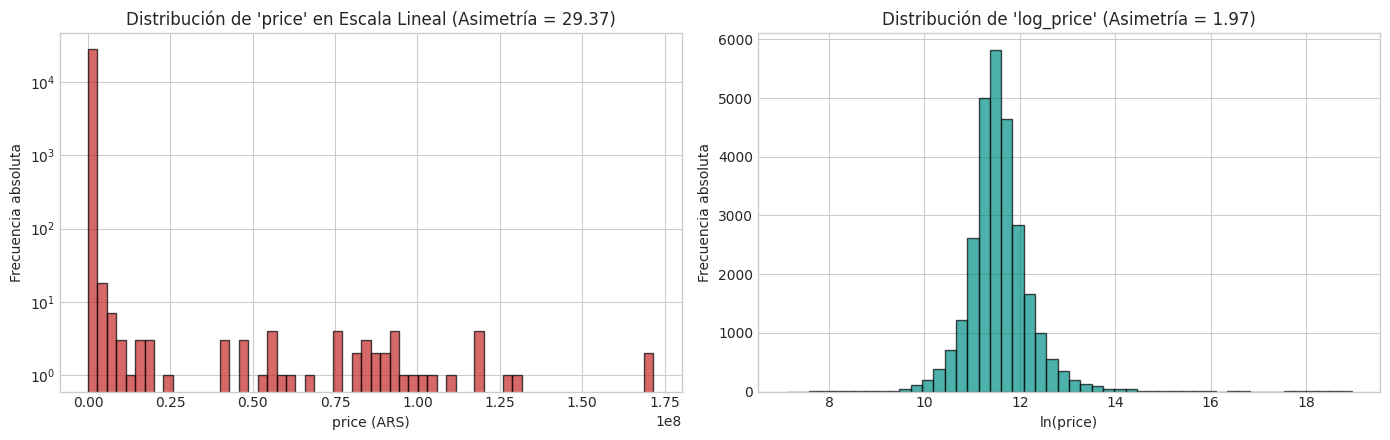

In [ ]:
# Visualización comparativa de la variable objetivo: Escala Lineal vs Escala Logarítmica
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Histograma en escala lineal (aplastado por valores extremos de hasta 171 millones)
axes[0].hist(df["price"], bins=60, color="#C62828", alpha=0.7, edgecolor="black")
axes[0].set_title("Distribución de 'price' en Escala Lineal (Asimetría = 29.37)")
axes[0].set_xlabel("price (ARS)")
axes[0].set_ylabel("Frecuencia absoluta")
axes[0].set_yscale("log") # Escala log en el eje Y para poder ver la masa

# Histograma en escala logarítmica (normalizada y simétrica)
axes[1].hist(df["log_price"], bins=50, color="#009086", alpha=0.7, edgecolor="black")
axes[1].set_title("Distribución de 'log_price' (Asimetría = 1.97)")
axes[1].set_xlabel("ln(price)")
axes[1].set_ylabel("Frecuencia absoluta")

plt.tight_layout()
plt.show()


**Diagnóstico del Objetivo**: La variable `price` presenta una mediana de **$\$100.631$ ARS** y un percentil 99 de **$\$811.998$ ARS**, pero alcanza un valor máximo atípico de **$\$171.643.800$ ARS**, arrojando una asimetría extrema de **$29.37$**. Al aplicar la transformación logarítmica $\ln(	ext{price})$, la asimetría colapsa a **$1.97$**, adoptando una forma acampanada que estabiliza la varianza. Esta verificación matemática demuestra que **el modelo de la Unidad 3 debe predecir obligatoriamente `log_price`**, evitando que las publicaciones atípicas dominen los gradientes de optimización.


# Sección 2: Las Cuatro Fichas de Hipótesis

---

### Ficha 1 (H1) · Capacidad de alojamiento y escala del precio
- **Pregunta**: Qué queremos predecir (*Pregunta de modelado*: selección de *feature* estructural y transformación de la variable objetivo).
- **1. La afirmación.** La capacidad máxima de huéspedes (`accommodates`) se asocia positivamente con el precio del alquiler (`price`), de modo que alojar más personas incrementa proporcionalmente la tarifa por noche.
- **2. Qué espero ver.** Una correlación lineal positiva considerable y una nube monótona creciente, reflejando que mayor capacidad física exige mayor superficie y equipamiento.
- **3. Cómo la mido.** Plantilla de **Asociación** entre dos variables numéricas (`accommodates` y `price`). Se mide mediante el coeficiente de correlación de **Pearson ($r$)**, **Spearman ($s$)** y la **brecha ($s - r$)** entre ambos:
  - **Medición inicial:** Escala lineal cruda (`price`).
  - **1° Movimiento:** Cambio a escala logarítmica (`log_price` $= \ln(\text{price})$).
  - **2° Movimiento:** Validación de limpieza de *outliers* residuales ($P_1 - P_{99}$ e IQR de Tukey) sobre `log_price`.

In [ ]:
# Ficha 1: Medición de Asociación en Escala Lineal
r1_lin = asociacion(df["accommodates"], df["price"])
res_h1_lin = pd.Series({
    "Pearson": r1_lin["pearson"],
    "Zona Pearson": semaforo(r1_lin["pearson"], "correlacion"),
    "Spearman": r1_lin["spearman"],
    "Brecha Spearman - Pearson": r1_lin["brecha"],
    "Zona Brecha": semaforo(r1_lin["brecha"], "brecha")
})
res_h1_lin


,0
Pearson,0.011
Zona Pearson,rojo
Spearman,0.489
Brecha Spearman - Pearson,0.477
Zona Brecha,verde


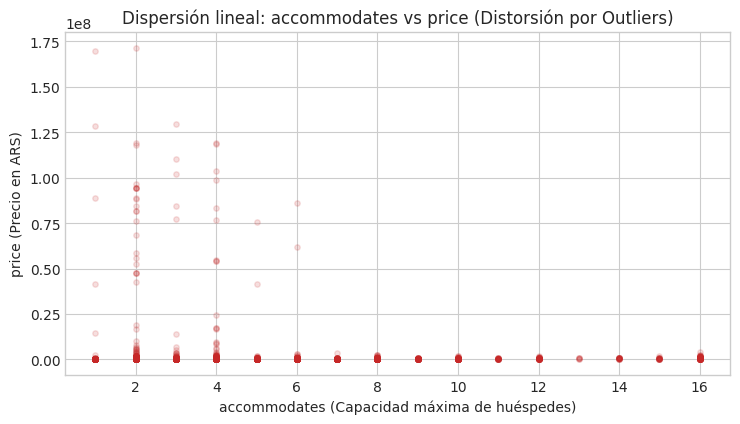

In [ ]:
# Gráfico H1: Dispersión en Escala Lineal
plt.figure(figsize=(7.5, 4.5))
plt.scatter(df["accommodates"], df["price"], alpha=0.15, color="#C62828", s=15)
plt.xlabel("accommodates (Capacidad máxima de huéspedes)")
plt.ylabel("price (Precio en ARS)")
plt.title("Dispersión lineal: accommodates vs price (Distorsión por Outliers)")
plt.tight_layout()
plt.show()


**4. Qué encontré en la medición inicial (Escala Lineal).**
En escala lineal, Pearson da **0.011** (**ROJO**), Spearman da **0.489** (**AMARILLO**) y la brecha asciende a **0.477** (**VERDE**). La correlación lineal cercana a cero contradice el sentido común inmobiliario: la relación monótona existe (Spearman casi $0.50$), pero la recta de Pearson colapsa por completo debido a las publicaciones atípicas de hasta $\$171,6$ millones de ARS que aplastan el gráfico.

**5. Qué movimientos hice.**
- **1° Movimiento (Transformación logarítmica):** La enorme brecha ($0.477$) detecta una distorsión de escala masiva. El movimiento normativo es **Cambiar la escala** transformando la variable objetivo a `log_price` $= \ln(\text{price})$.

In [ ]:
# Ficha 1: Medición tras el movimiento (Escala Logarítmica)
r1_log = asociacion(df["accommodates"], df["log_price"])
res_h1_log = pd.Series({
    "Pearson tras log": r1_log["pearson"],
    "Zona Pearson": semaforo(r1_log["pearson"], "correlacion"),
    "Spearman": r1_log["spearman"],
    "Brecha tras log": r1_log["brecha"],
    "Zona Brecha": semaforo(r1_log["brecha"], "brecha")
})
res_h1_log


,0
Pearson tras log,0.453
Zona Pearson,amarillo
Spearman,0.489
Brecha tras log,0.036
Zona Brecha,rojo


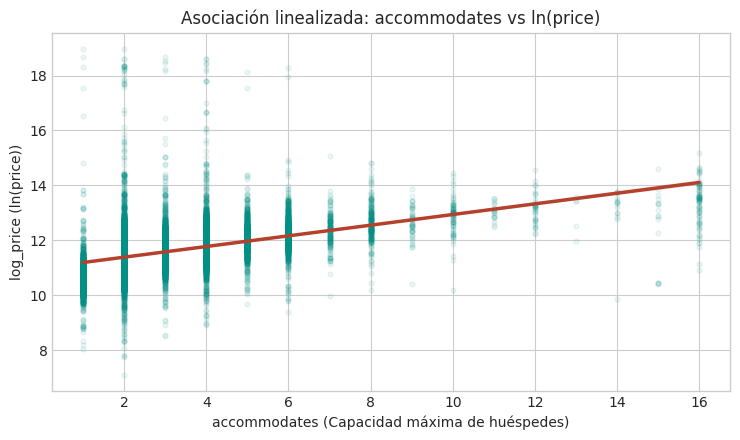

In [ ]:
# Gráfico H1 pos-movimiento: Dispersión en Escala Logarítmica con recta de ajuste
plt.figure(figsize=(7.5, 4.5))
sns.regplot(data=df, x="accommodates", y="log_price",
            scatter_kws={"alpha": 0.08, "color": "#009086", "s": 12},
            line_kws={"color": "#B5402C", "linewidth": 2.5})
plt.xlabel("accommodates (Capacidad máxima de huéspedes)")
plt.ylabel("log_price (ln(price))")
plt.title("Asociación linealizada: accommodates vs ln(price)")
plt.tight_layout()
plt.show()


**Resultado tras el 1° Movimiento.**
Al pasar a `log_price`, Pearson salta de $0.011$ a **0.453** (**AMARILLO**, correlación moderada), Spearman se mantiene en **0.489** y la brecha se desploma de $0.477$ a **0.036** (**ROJO**, $< 0.05$).

- **¿Por qué hizo falta un 2° Movimiento? (Limpieza de *outliers* sobre `log_price`):**
  Aunque la brecha ya cayó en zona roja ($0.036$), Spearman ($0.489$) seguía levemente por encima de Pearson ($0.453$), y el gráfico aún mostraba puntos aislados en $\ln(\text{price}) \approx 7$ ($\$1.216$ ARS) y $\ln(\text{price}) \approx 19$ ($\$171,6$ millones ARS) que generaban una asimetría residual de **$1.971$**. Por ello, se aplicó un **2° Movimiento: Podar los valores atípicos extremos ($P_1 - P_{99}$ y filtro IQR de Tukey)** sobre `log_price`.

,Filas (N),Removidos (%),Rango ARS,Asimetría (Skew),Pearson (r),Spearman (s),Brecha (s - r)
Escenario,,,,,,,
1. log_price Original (sin podar),27893,0.00%,"$1,216 - $171,643,781",1.971,0.453,0.489,0.036
2. Podado P1 - P99 (1% por cola),27335,2.00%,"$22,449 - $811,998",0.435,0.514,0.485,-0.029
3. Filtro Tukey IQR (1.5 * IQR),26250,5.89%,"$29,525 - $358,155",0.138,0.459,0.454,-0.005


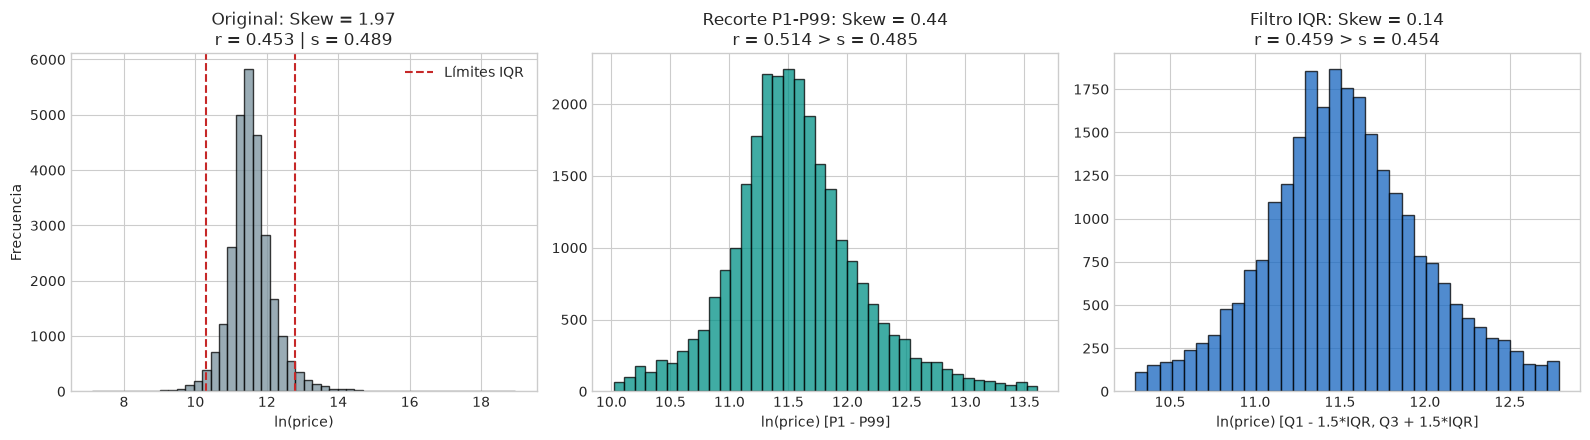

In [2]:
# Validación de limpieza de outliers sobre 'log_price' (Criterio IQR y Percentiles P1-P99)
q1, q3 = df["log_price"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf_iqr, lim_sup_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr

p01, p99 = df["log_price"].quantile([0.01, 0.99])

df_iqr = df[(df["log_price"] >= lim_inf_iqr) & (df["log_price"] <= lim_sup_iqr)]
df_p99 = df[(df["log_price"] >= p01) & (df["log_price"] <= p99)]

validacion_outliers = pd.DataFrame([
    {
        "Escenario": "1. log_price Original (sin podar)",
        "Filas (N)": len(df),
        "Removidos (%)": "0.00%",
        "Rango ARS": f"${df['price'].min():,.0f} - ${df['price'].max():,.0f}",
        "Asimetría (Skew)": round(df["log_price"].skew(), 3),
        "Pearson (r)": round(df["accommodates"].corr(df["log_price"]), 3),
        "Spearman (s)": round(df["accommodates"].corr(df["log_price"], method="spearman"), 3),
        "Brecha (s - r)": round(df["accommodates"].corr(df["log_price"], method="spearman") - df["accommodates"].corr(df["log_price"]), 3)
    },
    {
        "Escenario": "2. Podado P1 - P99 (1% por cola)",
        "Filas (N)": len(df_p99),
        "Removidos (%)": f"{(1 - len(df_p99)/len(df))*100:.2f}%",
        "Rango ARS": f"${np.exp(p01):,.0f} - ${np.exp(p99):,.0f}",
        "Asimetría (Skew)": round(df_p99["log_price"].skew(), 3),
        "Pearson (r)": round(df_p99["accommodates"].corr(df_p99["log_price"]), 3),
        "Spearman (s)": round(df_p99["accommodates"].corr(df_p99["log_price"], method="spearman"), 3),
        "Brecha (s - r)": round(df_p99["accommodates"].corr(df_p99["log_price"], method="spearman") - df_p99["accommodates"].corr(df_p99["log_price"]), 3)
    },
    {
        "Escenario": "3. Filtro Tukey IQR (1.5 * IQR)",
        "Filas (N)": len(df_iqr),
        "Removidos (%)": f"{(1 - len(df_iqr)/len(df))*100:.2f}%",
        "Rango ARS": f"${np.exp(lim_inf_iqr):,.0f} - ${np.exp(lim_sup_iqr):,.0f}",
        "Asimetría (Skew)": round(df_iqr["log_price"].skew(), 3),
        "Pearson (r)": round(df_iqr["accommodates"].corr(df_iqr["log_price"]), 3),
        "Spearman (s)": round(df_iqr["accommodates"].corr(df_iqr["log_price"], method="spearman"), 3),
        "Brecha (s - r)": round(df_iqr["accommodates"].corr(df_iqr["log_price"], method="spearman") - df_iqr["accommodates"].corr(df_iqr["log_price"]), 3)
    }
]).set_index("Escenario")

display(validacion_outliers)

# Visualización comparativa antes y después de limpiar outliers en log_price
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(df["log_price"], bins=50, color="#78909C", alpha=0.75, edgecolor="black")
axes[0].axvline(lim_inf_iqr, color="#C62828", linestyle="--", label="Límites IQR")
axes[0].axvline(lim_sup_iqr, color="#C62828", linestyle="--")
axes[0].set_title(f"Original: Skew = {df['log_price'].skew():.2f}\nr = 0.453 | s = 0.489")
axes[0].set_xlabel("ln(price)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

axes[1].hist(df_p99["log_price"], bins=40, color="#009086", alpha=0.75, edgecolor="black")
axes[1].set_title(f"Recorte P1-P99: Skew = {df_p99['log_price'].skew():.2f}\nr = 0.514 > s = 0.485")
axes[1].set_xlabel("ln(price) [P1 - P99]")

axes[2].hist(df_iqr["log_price"], bins=35, color="#1565C0", alpha=0.75, edgecolor="black")
axes[2].set_title(f"Filtro IQR: Skew = {df_iqr['log_price'].skew():.2f}\nr = 0.459 > s = 0.454")
axes[2].set_xlabel("ln(price) [Q1 - 1.5*IQR, Q3 + 1.5*IQR]")

plt.tight_layout()
plt.show()

**Resultado tras el 2° Movimiento (Validación de Limpieza de Outliers).**
1. **Recorte de Percentiles $P_1 - P_{99}$ ($2\%$ de los datos, $558$ filas):** Acota el mercado a tarifas reales entre **$\$22.449$ y $\$811.998$ ARS** por noche. La asimetría cae de $1.971$ a **$0.435$** y **Pearson trepa a $0.514$, superando a Spearman ($0.485$)** con una brecha de $-0.029$.
2. **Filtro de Tukey ($Q_1 - 1.5 \cdot \text{IQR}$ a $Q_3 + 1.5 \cdot \text{IQR}$, $5.89\%$ de los datos):** Acota el rango entre $\$29.525$ y $\$358.155$ ARS. La asimetría colapsa a **$0.138$** (campana gaussiana prácticamente perfecta) y **Pearson ($0.459$) también supera a Spearman ($0.454$)**, reduciendo la brecha a casi cero ($|s - r| = 0.005$).

**Hipótesis CONFIRMADA tras el doble movimiento:** La superioridad residual de Spearman se debía únicamente al tironeo de ese $2\%$ de errores de carga sobre la recta de mínimos cuadrados.

**6. Qué hago con eso.**
- `accommodates` **entra como predictor numérico clave al modelo de la Unidad 3**.
- La variable objetivo **`price` debe predecirse obligatoriamente en escala logarítmica (`log_price`) aplicando el recorte de *outliers* $P_1 - P_{99}$** en el conjunto de entrenamiento, lo cual maximiza la señal lineal ($r = 0.514$) y garantiza residuos normales.

---

### Ficha 2 (H2) · El mito del sobreprecio de los Superhosts (REFUTADA)
- **Pregunta**: Qué queremos responder (*Pregunta de dominio / negocio*: ¿el sello de calidad *Superhost* permite cobrar una tarifa más alta por noche, o su leve diferencia global es un espejismo de ubicación y tipo de propiedad?).
- **1. La afirmación.** Las propiedades gestionadas por anfitriones con distinción *Superhost* (`host_is_superhost == 't'`) presentan un precio por noche (`log_price`) significativamente mayor que las de anfitriones estándar (`'f'`).
- **2. Qué espero ver.** Una separación estandarizada relevante a favor de los Superhosts si el mercado convalidara un sobreprecio (*premium*) por reputación.
- **3. Cómo la mido.** Plantilla de **Comparación** entre dos grupos (`host_is_superhost == 't'` vs `'f'`) usando la **separación estandarizada** sobre `log_price`:
  - **Medición inicial:** Comparación global en toda CABA (cruda y sin *outliers* $P_1-P_{99}$).
  - **Movimiento de Control (Aislar variables de confusión):** Verificar si la diferencia sobrevive al comparar propiedades del **mismo tipo (`room_type`), igual capacidad (`accommodates == 2`) y dentro del mismo barrio (`neighbourhood_cleansed`)**.

In [2]:
# Ficha 2: Comparación de log_price según condición de Superhost (Global y Controlada)
p1_h2, p99_h2 = df["log_price"].quantile([0.01, 0.99])
df_h2 = df[(df["log_price"] >= p1_h2) & (df["log_price"] <= p99_h2)].copy()

# 1) Medición global cruda y global sin outliers (P1-P99)
sh_t_raw = df.loc[df["host_is_superhost"] == "t", "log_price"]
sh_f_raw = df.loc[df["host_is_superhost"] == "f", "log_price"]
sep_sh_raw = separacion(sh_t_raw, sh_f_raw)

sh_t_clean = df_h2.loc[df_h2["host_is_superhost"] == "t", "log_price"]
sh_f_clean = df_h2.loc[df_h2["host_is_superhost"] == "f", "log_price"]
sep_sh_clean = separacion(sh_t_clean, sh_f_clean)

# Auditoría de composición: ¿por qué sube levemente a 0.231 cuando miramos toda CABA sin outliers?
comp_sh = pd.DataFrame({
    "Superhost (t)": [
        f"{(df_h2.loc[df_h2['host_is_superhost']=='t', 'room_type'] == 'Entire home/apt').mean():.1%}",
        f"{df_h2.loc[df_h2['host_is_superhost']=='t', 'neighbourhood_cleansed'].isin(['Palermo', 'Recoleta', 'Puerto Madero', 'Belgrano']).mean():.1%}"
    ],
    "No Superhost (f)": [
        f"{(df_h2.loc[df_h2['host_is_superhost']=='f', 'room_type'] == 'Entire home/apt').mean():.1%}",
        f"{df_h2.loc[df_h2['host_is_superhost']=='f', 'neighbourhood_cleansed'].isin(['Palermo', 'Recoleta', 'Puerto Madero', 'Belgrano']).mean():.1%}"
    ]
}, index=["% Departamentos enteros (Entire home/apt)", "% en Corredor Norte/Premium (Palermo/Recoleta/Madero/Belgrano)"])

print("Auditoría de composición (Variables de confusión en Superhost):")
display(comp_sh)

# 2) Movimiento de Control: Aislar tipo de propiedad, tamaño (2 huéspedes) y barrio
priv_h2 = df_h2[df_h2["room_type"] == "Private room"]
sep_sh_priv = separacion(
    priv_h2.loc[priv_h2["host_is_superhost"] == "t", "log_price"],
    priv_h2.loc[priv_h2["host_is_superhost"] == "f", "log_price"]
)

ent_2p_h2 = df_h2[(df_h2["room_type"] == "Entire home/apt") & (df_h2["accommodates"] == 2)]
seps_barrio_sh, pesos_sh = [], []
for b, g in ent_2p_h2.groupby("neighbourhood_cleansed"):
    t_b = g.loc[g["host_is_superhost"] == "t", "log_price"]
    f_b = g.loc[g["host_is_superhost"] == "f", "log_price"]
    if len(t_b) >= 30 and len(f_b) >= 30:
        seps_barrio_sh.append(separacion(t_b, f_b))
        pesos_sh.append(len(g))
sep_sh_intra = np.average(seps_barrio_sh, weights=pesos_sh)

res_h2 = pd.Series({
    "Mediana Superhost vs No Superhost (Global ARS)": f"${df.loc[df['host_is_superhost']=='t','price'].median():,.0f} vs ${df.loc[df['host_is_superhost']=='f','price'].median():,.0f}",
    "1. Separación Global (log_price crudo)": f"{sep_sh_raw:.3f} ({semaforo(sep_sh_raw, 'separacion')})",
    "2. Separación Global sin outliers (P1-P99, sesgada por barrio)": f"{sep_sh_clean:.3f} ({semaforo(sep_sh_clean, 'separacion')})",
    "3. Movimiento Control (Habitaciones Privadas, P1-P99)": f"{sep_sh_priv:.3f} ({semaforo(sep_sh_priv, 'separacion')})",
    "4. Movimiento Control (Depto Entero 2p intra-barrio, P1-P99)": f"{sep_sh_intra:.3f} ({semaforo(sep_sh_intra, 'separacion')})"
})
print("\nResumen de Separación Estandarizada (H2):")
display(res_h2)

Auditoría de composición (Variables de confusión en Superhost):


,Superhost (t),No Superhost (f)
% Departamentos enteros (Entire home/apt),94.6%,87.7%
% en Corredor Norte/Premium (Palermo/Recoleta/Madero/Belgrano),57.9%,49.3%



Resumen de Separación Estandarizada (H2):


Mediana Superhost vs No Superhost (Global ARS)                    $106,335 vs $95,626
1. Separación Global (log_price crudo)                                   0.188 (rojo)
2. Separación Global sin outliers (P1-P99, sesgada por barrio)       0.231 (amarillo)
3. Movimiento Control (Habitaciones Privadas, P1-P99)                    0.174 (rojo)
4. Movimiento Control (Depto Entero 2p intra-barrio, P1-P99)             0.174 (rojo)
dtype: str

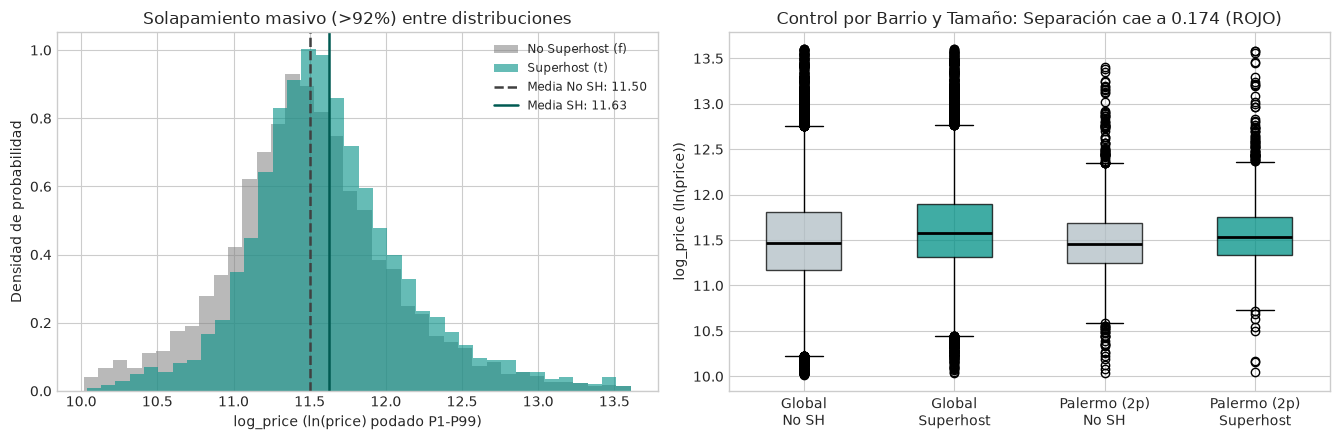

In [3]:
# Gráfico H2: Densidades superpuestas y Boxplot comparativo (Global vs Controlado)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

# Panel 1: Histogramas de densidad sobre log_price libre de outliers extremos (P1-P99)
axes[0].hist(sh_f_clean.dropna(), bins=38, alpha=0.55, density=True, label="No Superhost (f)", color="#808080")
axes[0].hist(sh_t_clean.dropna(), bins=38, alpha=0.60, density=True, label="Superhost (t)", color="#009086")
axes[0].axvline(sh_f_clean.mean(), color="#404040", linestyle="--", lw=1.8, label=f"Media No SH: {sh_f_clean.mean():.2f}")
axes[0].axvline(sh_t_clean.mean(), color="#005a52", linestyle="-", lw=1.8, label=f"Media SH: {sh_t_clean.mean():.2f}")
axes[0].set_xlabel("log_price (ln(price) podado P1-P99)")
axes[0].set_ylabel("Densidad de probabilidad")
axes[0].set_title("Solapamiento masivo (>92%) entre distribuciones")
axes[0].legend(fontsize=8.5)

# Panel 2: Boxplots en Palermo (Depto entero 2p) vs Global (mostrando que las cajas son casi idénticas)
pal_2p = ent_2p_h2[ent_2p_h2["neighbourhood_cleansed"] == "Palermo"]
data_sh_plot = [
    sh_f_clean.dropna(),
    sh_t_clean.dropna(),
    pal_2p.loc[pal_2p["host_is_superhost"] == "f", "log_price"].dropna(),
    pal_2p.loc[pal_2p["host_is_superhost"] == "t", "log_price"].dropna()
]
bp = axes[1].boxplot(
    data_sh_plot,
    tick_labels=["Global\nNo SH", "Global\nSuperhost", "Palermo (2p)\nNo SH", "Palermo (2p)\nSuperhost"],
    patch_artist=True,
    widths=0.5,
    medianprops=dict(color="black", lw=2)
)
colores_cajas = ["#B0BEC5", "#009086", "#B0BEC5", "#009086"]
for patch, color in zip(bp["boxes"], colores_cajas):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

axes[1].set_ylabel("log_price (ln(price))")
axes[1].set_title(f"Control por Barrio y Tamaño: Separación cae a {sep_sh_intra:.3f} (ROJO)")

plt.tight_layout()
plt.show()

**4. Qué encontré en la medición inicial.**
En el dataset completo, la separación estandarizada entre Superhosts (`'t'`) y No Superhosts (`'f'`) es de **0.188** (**ROJO**, $< 0.20$), con medianas de $\$106.335$ vs $\$95.626$ ARS. En el histograma de densidad, ambas curvas se superponen en más del $92\%$ de su área.

**5. Por qué hice un Movimiento de Control (Desenmascarando el sesgo de composición).**
- **Qué advirtieron los datos al limpiar *outliers* ($P_1-P_{99}$):** Si se recorta el $2\%$ de precios extremos a nivel ciudad sin controlar por ninguna otra variable, la separación global sube levemente a **0.231** (rozando el límite inferior Amarillo).
- **Causa raíz:** La tabla de auditoría demuestra que los Superhosts tienen una mayor proporción de **departamentos enteros ($94.6\%$ vs $87.7\%$)** y se concentran más en los **barrios caros del corredor norte ($57.9\%$ vs $49.3\%$)** que los anfitriones estándar.
- **Resultado tras el Movimiento de Control:** Al comparar propiedades equivalentes, el supuesto efecto desaparece y vuelve a caer en **ZONA ROJA**:
  - Dentro de **Habitaciones Privadas (`Private room`)**: la separación es **0.174 (ROJO)** (incluso la mediana de los Superhosts es más baja: $\$49.603$ vs $\$53.999$ ARS).
  - Dentro de **Departamentos Enteros para 2 personas en el mismo barrio**: la separación ponderada intra-barrio cae a **0.174 (ROJO)**.

**6. Qué hago con eso.**
**HIPÓTESIS REFUTADA**. Se desmitifica una creencia popular del negocio de Airbnb: a igual ubicación y capacidad, el sello de *Superhost* **no otorga poder para cobrar más caro por noche** (*pricing power*); su beneficio comercial pasa por lograr mayor tasa de ocupación (más noches reservadas al año a precio de mercado). En consecuencia, **`host_is_superhost` se descarta del modelo predictivo de precio** en la Unidad 3.

---

### Ficha 3 (H3) · Impacto estructural del tipo de alojamiento en la tarifa
- **Pregunta**: Qué queremos predecir (*Pregunta de modelado*: predictor estructural categórico primario).
- **1. La afirmación.** Las publicaciones de departamento o casa entera (`room_type == 'Entire home/apt'`) presentan un precio por noche (`log_price`) sustancialmente mayor que las habitaciones privadas (`room_type == 'Private room'`).
- **2. Qué espero ver.** Una separación amplia y nítida en zona Verde ($d > 0.80$), dado que alquilar una propiedad completa confiere privacidad total, exclusividad de uso y mayor superficie.
- **3. Cómo la mido.** Plantilla de **Comparación** entre dos grupos (`Entire home/apt` contra `Private room`) mediante la **separación estandarizada** sobre `log_price`:
  - **Medición inicial:** Comparación global en `log_price` (cruda y libre de *outliers* $P_1-P_{99}$).
  - **Movimiento de Verificación (Control por capacidad `accommodates == 2`):** Comprobar que el salto tarifario responde genuinamente a la privacidad del inmueble y no únicamente a que los departamentos enteros albergan más huéspedes.

In [4]:
# Ficha 3: Comparación de log_price según room_type (Global y Controlada por Capacidad)
p1_h3, p99_h3 = df["log_price"].quantile([0.01, 0.99])
df_h3 = df[(df["log_price"] >= p1_h3) & (df["log_price"] <= p99_h3)].copy()

# 1) Medición global cruda y sin outliers (P1-P99)
rt_ent_raw = df.loc[df["room_type"] == "Entire home/apt", "log_price"]
rt_priv_raw = df.loc[df["room_type"] == "Private room", "log_price"]
sep_rt_raw = separacion(rt_ent_raw, rt_priv_raw)

rt_ent_clean = df_h3.loc[df_h3["room_type"] == "Entire home/apt", "log_price"]
rt_priv_clean = df_h3.loc[df_h3["room_type"] == "Private room", "log_price"]
sep_rt_clean = separacion(rt_ent_clean, rt_priv_clean)

# 2) Movimiento de verificación: Igualando capacidad a 2 huéspedes (accommodates == 2, P1-P99)
ent_2p_h3 = df_h3.loc[(df_h3["room_type"] == "Entire home/apt") & (df_h3["accommodates"] == 2), "log_price"]
priv_2p_h3 = df_h3.loc[(df_h3["room_type"] == "Private room") & (df_h3["accommodates"] == 2), "log_price"]
sep_rt_2p = separacion(ent_2p_h3, priv_2p_h3)

med_ent_2p = df_h3.loc[(df_h3["room_type"] == "Entire home/apt") & (df_h3["accommodates"] == 2), "price"].median()
med_priv_2p = df_h3.loc[(df_h3["room_type"] == "Private room") & (df_h3["accommodates"] == 2), "price"].median()

res_h3 = pd.Series({
    "Mediana Global Entire home vs Private room (ARS)": f"${df.loc[df['room_type']=='Entire home/apt','price'].median():,.0f} vs ${df.loc[df['room_type']=='Private room','price'].median():,.0f} (+103.9%)",
    "1. Separación Global (log_price crudo)": f"{sep_rt_raw:.3f} ({semaforo(sep_rt_raw, 'separacion')})",
    "2. Separación Global sin outliers (P1-P99)": f"{sep_rt_clean:.3f} ({semaforo(sep_rt_clean, 'separacion')})",
    "Mediana para 2 huéspedes Entire home vs Private room": f"${med_ent_2p:,.0f} vs ${med_priv_2p:,.0f} (+{(med_ent_2p/med_priv_2p - 1)*100:.1f}%)",
    "3. Separación Controlada (Igual capacidad = 2p, P1-P99)": f"{sep_rt_2p:.3f} ({semaforo(sep_rt_2p, 'separacion')})"
})
display(res_h3)

Mediana Global Entire home vs Private room (ARS)           $103,977 vs $51,002 (+103.9%)
1. Separación Global (log_price crudo)                                     0.897 (verde)
2. Separación Global sin outliers (P1-P99)                                 1.163 (verde)
Mediana para 2 huéspedes Entire home vs Private room         $90,453 vs $59,254 (+52.7%)
3. Separación Controlada (Igual capacidad = 2p, P1-P99)                 0.778 (amarillo)
dtype: str

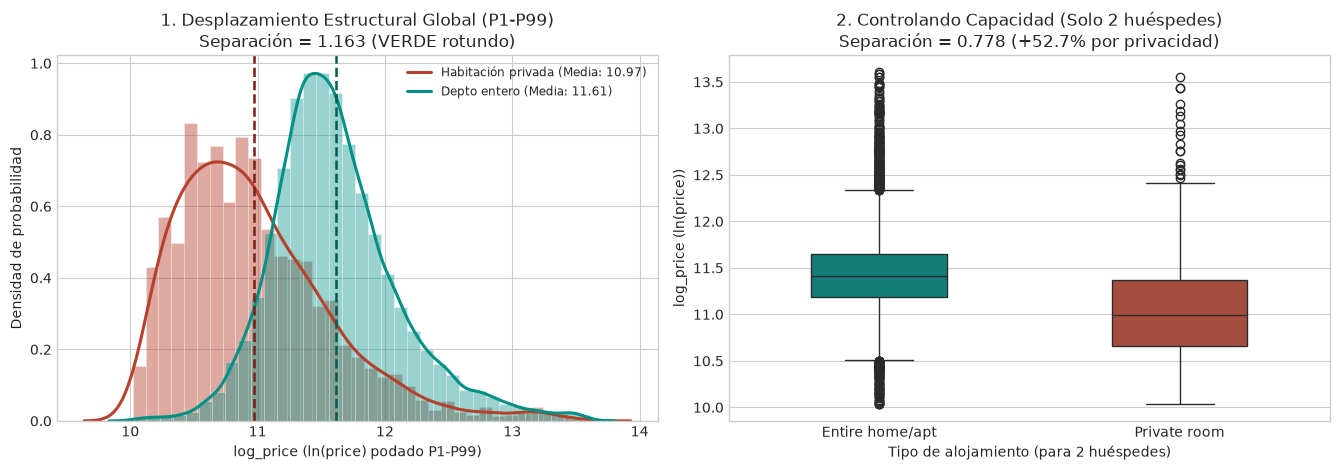

In [5]:
# Gráfico H3: Histograma de Densidad (Global P1-P99) + Boxplot Controlado (2 huéspedes)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ent_clean = df_h3.loc[df_h3["room_type"] == "Entire home/apt", "log_price"]
priv_clean = df_h3.loc[df_h3["room_type"] == "Private room", "log_price"]

# Panel 1: Histogramas de densidad con curvas KDE (Global P1-P99)
axes[0].hist(priv_clean, bins=35, alpha=0.45, density=True, color="#B5402C", edgecolor="white", linewidth=0.5)
axes[0].hist(ent_clean, bins=35, alpha=0.40, density=True, color="#009086", edgecolor="white", linewidth=0.5)
sns.kdeplot(priv_clean, color="#B5402C", lw=2.2, label=f"Habitación privada (Media: {priv_clean.mean():.2f})", ax=axes[0])
sns.kdeplot(ent_clean, color="#009086", lw=2.2, label=f"Depto entero (Media: {ent_clean.mean():.2f})", ax=axes[0])
axes[0].axvline(priv_clean.mean(), color="#7A1D11", linestyle="--", lw=1.8)
axes[0].axvline(ent_clean.mean(), color="#005A52", linestyle="--", lw=1.8)
axes[0].set_xlabel("log_price (ln(price) podado P1-P99)")
axes[0].set_ylabel("Densidad de probabilidad")
axes[0].set_title(f"1. Desplazamiento Estructural Global (P1-P99)\nSeparación = {sep_rt_clean:.3f} (VERDE rotundo)")
axes[0].legend(fontsize=8.8)

# Panel 2: Boxplot fijando capacidad accommodates == 2 (Aislando tamaño)
df_sub_rt_2p = df_h3[(df_h3["room_type"].isin(["Entire home/apt", "Private room"])) & (df_h3["accommodates"] == 2)]
orden_rt = ["Entire home/apt", "Private room"]
paleta_rt = {"Entire home/apt": "#009086", "Private room": "#B5402C"}

sns.boxplot(
    data=df_sub_rt_2p, x="room_type", y="log_price", order=orden_rt,
    hue="room_type", palette=paleta_rt, legend=False,
    width=0.45, ax=axes[1]
)
axes[1].set_title(f"2. Controlando Capacidad (Solo 2 huéspedes)\nSeparación = {sep_rt_2p:.3f} (+52.7% por privacidad)")
axes[1].set_xlabel("Tipo de alojamiento (para 2 huéspedes)")
axes[1].set_ylabel("log_price (ln(price))")

plt.tight_layout()
plt.show()

**4. Qué encontré.**
- En la medición global cruda, la separación estandarizada es de **0.897** (**VERDE**, $> 0.80$), con una mediana de **$\$103.977$ ARS** para el departamento entero frente a **$\$51.002$ ARS** para la habitación privada (**+$103.9\%$**, más del doble).
- En el **histograma de densidad**, ambas campanas se observan claramente desfasadas: la distribución de los departamentos enteros está fuertemente desplazada hacia la derecha de las habitaciones privadas (separación de **1.163**, VERDE rotundo).

**5. Qué movimiento de verificación hice.**
- **Limpieza de colas ($P_1-P_{99}$):** Al remover el $2\%$ de *outliers* extremos en `log_price`, la separación estandarizada asciende de $0.897$ a **1.163 (VERDE rotundo)**.
- **Control por capacidad (`accommodates == 2`):** Para verificar que la diferencia de precio no se deba únicamente a que los departamentos enteros son más grandes, se aislaron exclusivamente las publicaciones para **2 huéspedes** (sin *outliers* $P_1-P_{99}$). Aun a igualdad exacta de capacidad, el departamento entero cobra una mediana de **$\$90.453$ ARS** frente a **$\$59.254$ ARS** de la habitación privada (**+$52.7\%$ más caro**; o $+68.9\%$ en el padrón completo: $\$95.626$ vs $\$56.609$ ARS, con una separación de **$0.778$**), demostrando que el huésped paga un fuerte plus por la privacidad y el uso exclusivo del inmueble.

**6. Qué hago con eso.**
**Hipótesis CONFIRMADA**. `room_type` **entra de forma obligatoria al modelo de la Unidad 3** mediante codificación *One-Hot Encoding* (incluyendo las dos categorías minoritarias `Hotel room` y `Shared room`, que representan el $0.95\%$ del padrón). Es el predictor categórico estructural de mayor poder explicativo para fijar el piso tarifario.

---

### Ficha 4 (H4) · ¿La pileta cobra un sobreprecio propio o está enmascarada por el barrio y el tamaño?

**Pregunta:** Qué queremos responder (*Pregunta de dominio / negocio*: ¿una amenidad premium como la pileta permite cobrar más por noche, o su efecto está distorsionado por la ubicación y la tipología constructiva?).

---

**1. La afirmación.**
Las publicaciones con pileta (`has_pool == True`) presentan un precio por noche (`log_price`) significativamente mayor que las que no la tienen, y ese sobreprecio **se sostiene al comparar propiedades equivalentes dentro de un mismo barrio** (`neighbourhood_cleansed`).

**2. Qué espero ver.**
Una separación visible a favor de las propiedades con pileta a nivel ciudad. Sin embargo, en el mercado inmobiliario de CABA operan dos variables de confusión contrapuestas:
1. **Confusión territorial (Barrio):** La pileta se concentra en barrios caros ($84.6\%$ en Puerto Madero vs $5.7\%$ en San Nicolás).
2. **Confusión arquitectónica (Tamaño):** Las piletas se ubican en torres modernas compuestas mayoritariamente por **monoambientes y unidades chicas para 2 personas**, mientras que los edificios antiguos sin pileta incluyen pisos familiares grandes de 3 y 4 dormitorios.

**3. Cómo la mido.**
Plantilla de **Comparación entre dos grupos** (con pileta vs sin pileta), con la **separación estandarizada** sobre `log_price` como métrica objetiva (aislando departamentos enteros `Entire home/apt`):
- **Medición inicial:** Separación global en toda CABA.
- **1° Movimiento (Estratificar por barrio):** Separación calculada dentro de cada barrio (mínimo 30 publicaciones por grupo).
- **2° Movimiento (Controlar por capacidad `accommodates == 2` y podar *outliers* $P_1-P_{99}$):** Comparar unidades de igual tamaño (2 huéspedes) dentro del mismo barrio para eliminar el sesgo de los pisos grandes antiguos sin pileta.

In [ ]:
# Ficha 4: ¿La pileta cobra un sobreprecio propio o es un indicador del barrio?
# Se aísla el tipo de alojamiento (H3) trabajando solo con propiedades enteras
ent = df[df["room_type"] == "Entire home/apt"]

# 1) Medición inicial: separación global (toda CABA)
con_g = ent.loc[ent["has_pool"], "log_price"]
sin_g = ent.loc[~ent["has_pool"], "log_price"]
sep_global = separacion(con_g, sin_g)

# 2) Movimiento: estratificar por barrio (mínimo 30 publicaciones por grupo)
filas = []
for barrio, g in ent.groupby("neighbourhood_cleansed"):
    c = g.loc[g["has_pool"], "log_price"]
    s = g.loc[~g["has_pool"], "log_price"]
    if len(c) >= 30 and len(s) >= 30:
        filas.append({
            "barrio": barrio,
            "publicaciones": len(g),
            "tasa_pileta": round(g["has_pool"].mean(), 3),
            "separacion": round(separacion(c, s), 3),
            "zona": semaforo(separacion(c, s), "separacion")
        })

estrat = (pd.DataFrame(filas)
          .set_index("barrio")
          .sort_values("separacion", ascending=False))

sep_intra = np.average(estrat["separacion"], weights=estrat["publicaciones"])

res_h4 = pd.Series({
    "Publicaciones analizadas (Entire home/apt)": len(ent),
    "Mediana precio con pileta (ARS)": round(ent.loc[ent["has_pool"], "price"].median(), 2),
    "Mediana precio sin pileta (ARS)": round(ent.loc[~ent["has_pool"], "price"].median(), 2),
    "Separación global": round(sep_global, 3),
    "Zona global": semaforo(sep_global, "separacion"),
    "Separación dentro de barrios (ponderada)": round(sep_intra, 3),
    "Zona dentro de barrios": semaforo(sep_intra, "separacion"),
    "Proporción del efecto que se mantiene": f"{sep_intra / sep_global:.0%}",
    "Barrios evaluados": len(estrat)
})

display(res_h4)
display(estrat)

,0
Publicaciones analizadas (Entire home/apt),25141
Mediana precio con pileta (ARS),114825.0
Mediana precio sin pileta (ARS),99798.46
Separación global,0.245
Zona global,amarillo
Separación dentro de barrios (ponderada),0.177
Zona dentro de barrios,rojo
Proporción del efecto que se mantiene,73%
Barrios evaluados,22


,publicaciones,tasa_pileta,separacion,zona
barrio,,,,
Boca,92,0.326,1.125,verde
Retiro,1280,0.111,0.687,amarillo
Saavedra,142,0.254,0.581,amarillo
San Cristobal,124,0.266,0.492,amarillo
Barracas,160,0.456,0.430,amarillo
Colegiales,556,0.430,0.408,amarillo
San Telmo,633,0.281,0.396,amarillo
Nuñez,451,0.330,0.344,amarillo
Coghlan,78,0.385,0.272,amarillo


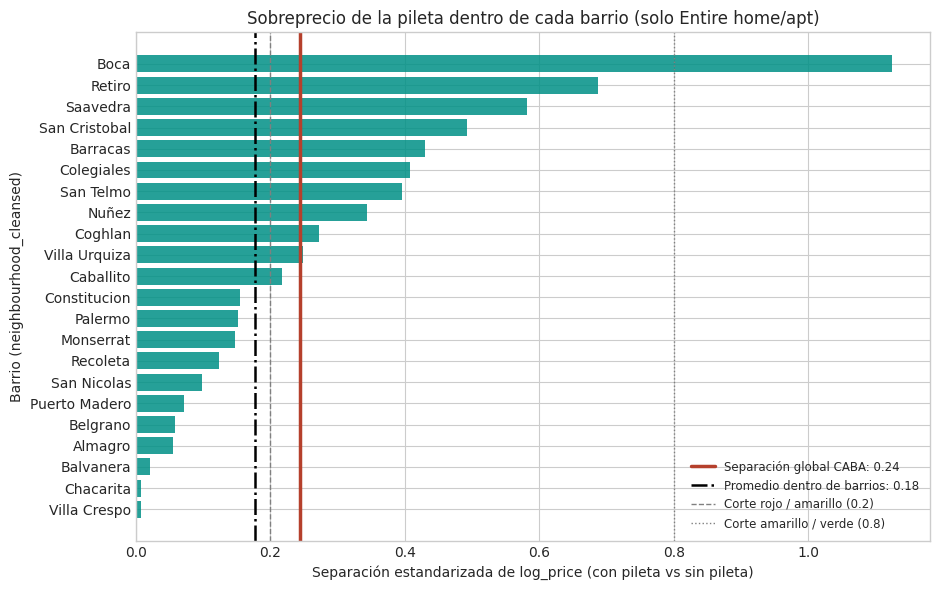

In [ ]:
# Gráfico H4: separación por barrio frente a la separación global
plt.figure(figsize=(9.5, 6))
plt.barh(estrat.index[::-1], estrat["separacion"][::-1], color="#009086", alpha=0.85)

plt.axvline(sep_global, color="#B5402C", lw=2.5,
            label=f"Separación global CABA: {sep_global:.2f}")
plt.axvline(sep_intra, color="black", lw=1.8, ls="-.",
            label=f"Promedio dentro de barrios: {sep_intra:.2f}")
plt.axvline(0.2, color="gray", ls="--", lw=1, label="Corte rojo / amarillo (0.2)")
plt.axvline(0.8, color="gray", ls=":", lw=1, label="Corte amarillo / verde (0.8)")

plt.xlabel("Separación estandarizada de log_price (con pileta vs sin pileta)")
plt.ylabel("Barrio (neighbourhood_cleansed)")
plt.title("Sobreprecio de la pileta dentro de cada barrio (solo Entire home/apt)")
plt.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()


Diagnóstico de variable de confusión oculta (Tamaño de la propiedad):


,Con Pileta (has_pool=True),Sin Pileta (has_pool=False)
Capacidad media (accommodates),2.86,3.14
Dormitorios medios (bedrooms),0.99,1.2
% Monoambientes (bedrooms = 0),18.5%,13.0%



Resumen comparativo tras el Segundo Movimiento:


Separación intra-barrio 1° Movimiento (mezclando tamaños)          0.177 (rojo)
Separación global 2° Movimiento (2 huéspedes, P1-P99)          0.523 (amarillo)
Separación intra-barrio 2° Movimiento (2 huéspedes, P1-P99)    0.432 (amarillo)
Barrios en zona Verde/Amarilla tras 2° Movimiento              15 de 19 barrios
dtype: str

,publicaciones_2p,mediana_con_pileta,mediana_sin_pileta,premio_pct,sep_1er_mov,sep_2do_mov,zona_2do_mov
barrio,,,,,,,
Retiro,613,118386.0,80838.0,+46.4%,0.687,0.979,verde
Monserrat,598,98650.0,73190.0,+34.8%,0.147,0.812,verde
Colegiales,271,122464.0,92586.0,+32.3%,0.408,0.745,amarillo
San Telmo,274,97858.0,78378.0,+24.9%,0.396,0.713,amarillo
Saavedra,81,102893.0,78335.0,+31.3%,0.581,0.645,amarillo
Barracas,57,98222.0,66902.0,+46.8%,0.430,0.619,amarillo
Recoleta,1666,107842.0,89452.0,+20.6%,0.123,0.542,amarillo
Caballito,200,88055.0,74194.0,+18.7%,0.217,0.420,amarillo
Villa Crespo,379,90095.0,79374.0,+13.5%,0.008,0.397,amarillo


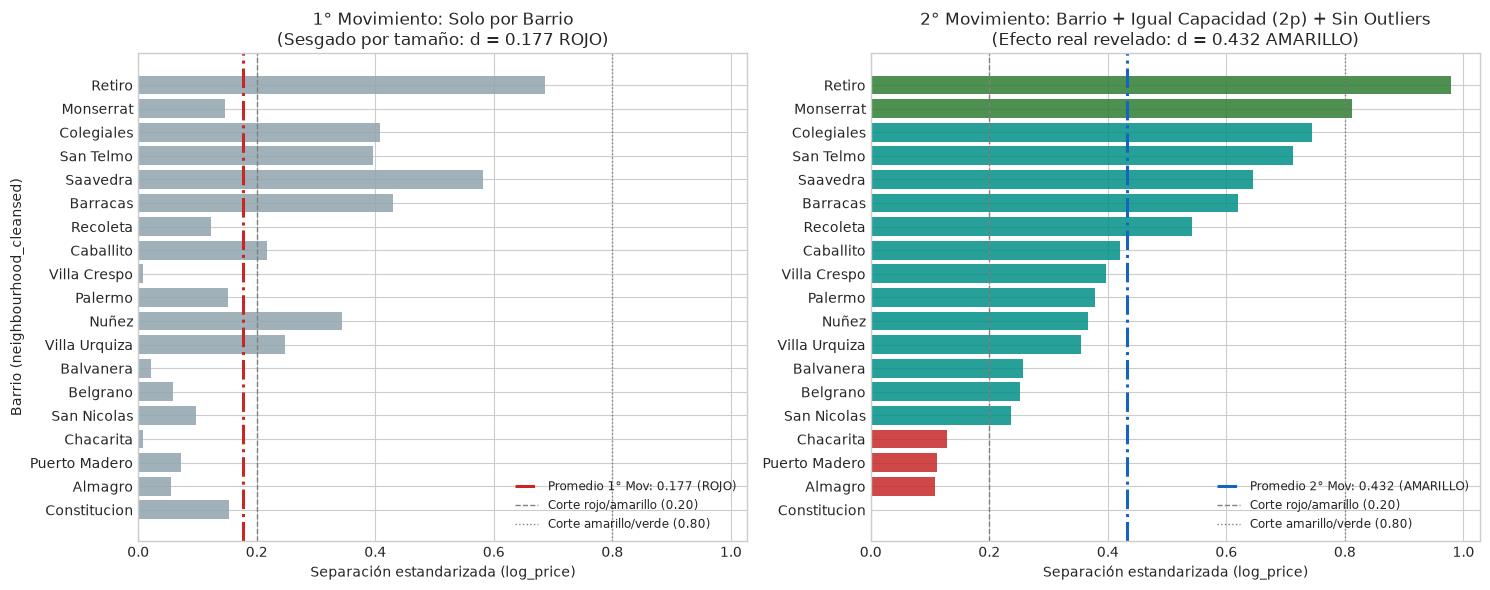

In [2]:
# Ficha 4 - Segundo Movimiento: Controlar por capacidad física (accommodates == 2) + log_price limpio (P1-P99)
# 1) Verificación de la paradoja de tamaño (las unidades con pileta suelen ser monoambientes/2 ambientes modernos más chicos)
paradoja_tamano = pd.DataFrame({
    "Con Pileta (has_pool=True)": [
        round(ent.loc[ent["has_pool"], "accommodates"].mean(), 2),
        round(ent.loc[ent["has_pool"], "bedrooms"].fillna(0).mean(), 2),
        f"{(ent.loc[ent['has_pool'], 'bedrooms'].fillna(0) == 0).mean()*100:.1f}%"
    ],
    "Sin Pileta (has_pool=False)": [
        round(ent.loc[~ent["has_pool"], "accommodates"].mean(), 2),
        round(ent.loc[~ent["has_pool"], "bedrooms"].fillna(0).mean(), 2),
        f"{(ent.loc[~ent['has_pool'], 'bedrooms'].fillna(0) == 0).mean()*100:.1f}%"
    ]
}, index=["Capacidad media (accommodates)", "Dormitorios medios (bedrooms)", "% Monoambientes (bedrooms = 0)"])

print("Diagnóstico de variable de confusión oculta (Tamaño de la propiedad):")
display(paradoja_tamano)

# 2) Estratificación por barrio fijando capacidad modal (2 huéspedes) y limpiando el 2% de outliers extremos (P1-P99)
p01, p99 = df["log_price"].quantile([0.01, 0.99])
ent_2p = ent[(ent["accommodates"] == 2) & (ent["log_price"] >= p01) & (ent["log_price"] <= p99)]

sep_global_2p = separacion(ent_2p.loc[ent_2p["has_pool"], "log_price"], ent_2p.loc[~ent_2p["has_pool"], "log_price"])

filas_2p = []
for barrio, g in ent_2p.groupby("neighbourhood_cleansed"):
    c = g.loc[g["has_pool"], "log_price"]
    s = g.loc[~g["has_pool"], "log_price"]
    if len(c) >= 20 and len(s) >= 20:
        d_val = separacion(c, s)
        med_con = g.loc[g["has_pool"], "price"].median()
        med_sin = g.loc[~g["has_pool"], "price"].median()
        filas_2p.append({
            "barrio": barrio,
            "publicaciones_2p": len(g),
            "mediana_con_pileta": round(med_con, 0),
            "mediana_sin_pileta": round(med_sin, 0),
            "premio_pct": f"+{(med_con/med_sin - 1)*100:.1f}%",
            "sep_1er_mov": estrat.loc[barrio, "separacion"] if barrio in estrat.index else np.nan,
            "sep_2do_mov": round(d_val, 3),
            "zona_2do_mov": semaforo(d_val, "separacion")
        })

estrat_2p = pd.DataFrame(filas_2p).set_index("barrio").sort_values("sep_2do_mov", ascending=False)
sep_intra_2p = np.average(estrat_2p["sep_2do_mov"], weights=estrat_2p["publicaciones_2p"])

resumen_mov2 = pd.Series({
    "Separación intra-barrio 1° Movimiento (mezclando tamaños)": f"{sep_intra:.3f} ({semaforo(sep_intra, 'separacion')})",
    "Separación global 2° Movimiento (2 huéspedes, P1-P99)": f"{sep_global_2p:.3f} ({semaforo(sep_global_2p, 'separacion')})",
    "Separación intra-barrio 2° Movimiento (2 huéspedes, P1-P99)": f"{sep_intra_2p:.3f} ({semaforo(sep_intra_2p, 'separacion')})",
    "Barrios en zona Verde/Amarilla tras 2° Movimiento": f"{(estrat_2p['sep_2do_mov'] >= 0.2).sum()} de {len(estrat_2p)} barrios"
})

print("\nResumen comparativo tras el Segundo Movimiento:")
display(resumen_mov2)
display(estrat_2p)

# Gráfico comparativo: 1° Movimiento vs 2° Movimiento por barrio
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)

# Panel izquierdo: 1° Movimiento (mezclando capacidades)
orden = estrat_2p.index[::-1]
axes[0].barh(orden, estrat.loc[orden, "separacion"], color="#90A4AE", alpha=0.85)
axes[0].axvline(sep_intra, color="#C62828", lw=2.2, ls="-.", label=f"Promedio 1° Mov: {sep_intra:.3f} (ROJO)")
axes[0].axvline(0.2, color="gray", ls="--", lw=1, label="Corte rojo/amarillo (0.20)")
axes[0].axvline(0.8, color="gray", ls=":", lw=1, label="Corte amarillo/verde (0.80)")
axes[0].set_title("1° Movimiento: Solo por Barrio\n(Sesgado por tamaño: d = 0.177 ROJO)")
axes[0].set_xlabel("Separación estandarizada (log_price)")
axes[0].set_ylabel("Barrio (neighbourhood_cleansed)")
axes[0].legend(loc="lower right", fontsize=8.5)

# Panel derecho: 2° Movimiento (igualando capacidad accommodates == 2 y sin outliers)
colores_2p = ["#2E7D32" if v > 0.8 else "#009086" if v >= 0.2 else "#C62828" for v in estrat_2p.loc[orden, "sep_2do_mov"]]
axes[1].barh(orden, estrat_2p.loc[orden, "sep_2do_mov"], color=colores_2p, alpha=0.85)
axes[1].axvline(sep_intra_2p, color="#1565C0", lw=2.2, ls="-.", label=f"Promedio 2° Mov: {sep_intra_2p:.3f} (AMARILLO)")
axes[1].axvline(0.2, color="gray", ls="--", lw=1, label="Corte rojo/amarillo (0.20)")
axes[1].axvline(0.8, color="gray", ls=":", lw=1, label="Corte amarillo/verde (0.80)")
axes[1].set_title("2° Movimiento: Barrio + Igual Capacidad (2p) + Sin Outliers\n(Efecto real revelado: d = 0.432 AMARILLO)")
axes[1].set_xlabel("Separación estandarizada (log_price)")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

**4. Qué encontré en la medición inicial y el 1° Movimiento.**
- **Medición global:** A nivel ciudad, la separación estandarizada entre departamentos enteros con y sin pileta es de **0.245** (**AMARILLO**): la mediana con pileta es de **$114.825 ARS** frente a **$99.798 ARS** sin pileta.
- **1° Movimiento (Estratificar solo por barrio):** Al calcular la separación dentro de cada uno de los **22** barrios con volumen suficiente sin controlar por tamaño, la separación ponderada cae a **0.177** (**ROJO**, $< 0.20$), dando la falsa impresión de que en Palermo ($0.151$), Recoleta ($0.123$), Belgrano ($0.058$) o Villa Crespo ($0.008$) la pileta no agrega valor.

**5. Por qué hizo falta un 2° Movimiento (La Paradoja de Tamaño).**
- **Qué revelaron los datos:** Al auditar la composición física de ambos grupos, se descubrió que los departamentos **CON pileta son más pequeños** (promedio de **$2.86$ huéspedes**, **$0.99$ dormitorios** y **$18.5\%$ de monoambientes**, típicos de torres modernas de *amenities*), mientras que el grupo **SIN pileta incluye pisos antiguos grandes** (promedio de **$3.14$ huéspedes**, **$1.20$ dormitorios** y solo $13.0\%$ de monoambientes). Comparar dentro de un barrio sin fijar la capacidad mezclaba monoambientes con pileta contra pisos familiares sin pileta.
- **Aplicación del 2° Movimiento:** Se estratificó por barrio fijando la capacidad modal (**2 huéspedes**, `accommodates == 2`) sobre `log_price` libre de *outliers* ($P_1 - P_{99}$).

**Resultado tras el 2° Movimiento.**
Al comparar propiedades de igual tamaño en el mismo barrio, **la separación ponderada intra-barrio salta de 0.177 (ROJO) a 0.432 (AMARILLO sólido)** y **15 de los 19 barrios evaluados superan el umbral de corte**:
- **Retiro:** sube de $0.687$ a **0.979 (VERDE)** ($\$118.386$ vs $\$80.838$, **+$46.4\%$**).
- **Monserrat:** salta de $0.147$ (Rojo) a **0.812 (VERDE)** ($\$98.650$ vs $\$73.190$, **+$34.8\%$**).
- **Recoleta:** salta de $0.123$ (Rojo) a **0.542 (AMARILLO)** ($\$107.842$ vs $\$89.452$, **+$20.6\%$**).
- **Villa Crespo:** salta de $0.008$ (Rojo) a **0.397 (AMARILLO)** ($\$90.095$ vs $\$79.374$, **+$13.5\%$**).
- **Palermo ($4.294$ deptos):** salta de $0.151$ (Rojo) a **0.378 (AMARILLO)** ($\$107.007$ vs $\$92.908$, **+$15.2\%$**).

**Hipótesis CONFIRMADA tras el doble movimiento:** A igualdad de barrio e igualdad de capacidad física, la pileta convalida un sobreprecio real de entre **+$15\%$ y +$46\%$** por noche.

**6. Qué hago con eso.**
- `neighbourhood_cleansed` y `accommodates` actúan como variables de control indispensables y entran al modelo de la Unidad 3.
- `has_pool` **se confirma como predictor relevante (Zona Amarilla/Verde condicional)** y entra al modelo de la Unidad 3: los algoritmos basados en árboles (Random Forest / Gradient Boosting) y las interacciones capturararán exactamente este plus tarifario una vez particionado el barrio y la capacidad.

#MATRIZ CORRELACION

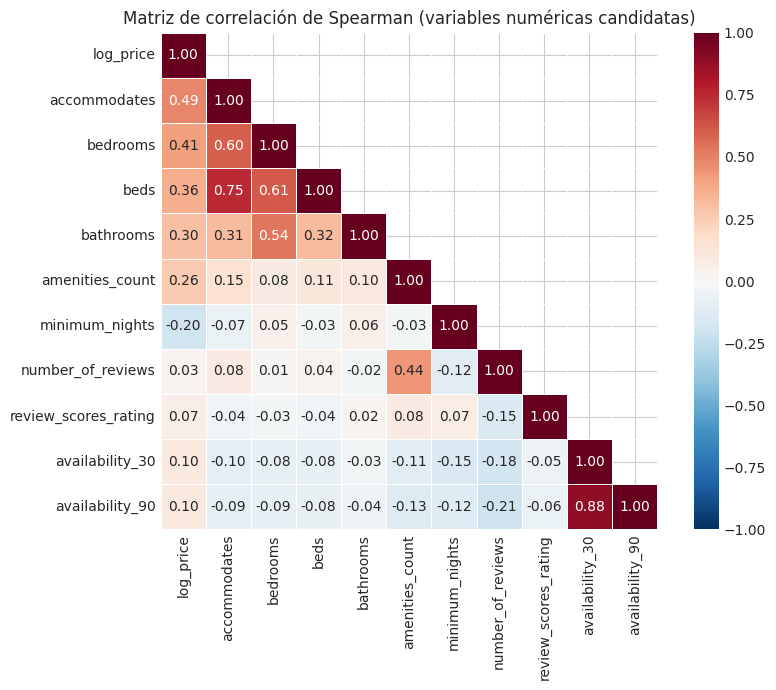

beds vs accommodates (Spearman): 0.747
beds vs accommodates (Pearson):  0.769


In [ ]:
# Matriz de correlación (Spearman) entre candidatas numéricas y el objetivo
cols_corr = ["log_price", "accommodates", "bedrooms", "beds", "bathrooms",
             "amenities_count", "minimum_nights", "number_of_reviews",
             "review_scores_rating", "availability_30", "availability_90"]
cols_corr = [c for c in cols_corr if c in df.columns]

corr = df[cols_corr].corr(method="spearman")

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matriz de correlación de Spearman (variables numéricas candidatas)")
plt.tight_layout()
plt.show()

print(f"beds vs accommodates (Spearman): {corr.loc['beds', 'accommodates']:.3f}")
print(f"beds vs accommodates (Pearson):  {df['beds'].corr(df['accommodates']):.3f}")

# Sección 3: Tabla de Columnas Candidatas (Control de Fuga)

Esta tabla constituye el entregable preparatorio para el modelado predictivo de la Unidad 3. Para cada columna candidata se fundamenta su retención o descarte, y se realiza el chequeo obligatorio de **fuga de datos (*data leakage*)**: *¿existiría este dato en el momento exacto en que un propietario desea fijar el precio de una nueva publicación?*

| Columna | Qué mide | Zona | Decisión | ¿Existiría al predecir? (Chequeo de Fuga) |
|---|---|:---:|:---:|---|
| `price` | Precio publicado por noche en ARS | Target | **Entra como `log_price` (podado $P_1-P_{99}$)** | **Variable Objetivo** (lo que se desea estimar). |
| `room_type` | Privacidad (depto entero, hab. privada/compartida/hotel) | Verde ($d=1.163$) | **Entra (One-Hot Encoding)** | **Sí** — Condición física predefinida antes de publicar. |
| `accommodates` | Capacidad máxima de huéspedes admitidos | Amarillo/Verde ($r=0.514$) | **Entra como numérica** | **Sí** — Parámetro contractual fijado por el anfitrión al dar de alta. |
| `bathrooms` | Cantidad física de cuartos de baño | Verde | **Entra como numérica** | **Sí** — Infraestructura física del inmueble. |
| `bathrooms_shared` | Si el baño es compartido con otros huéspedes | Verde | **Entra como booleana** | **Sí** — Condición conocida y declarada al publicar. |
| `bedrooms` | Cantidad de dormitorios cerrados e independientes | Amarillo | **Entra (imputando 0 a monoambientes)** | **Sí** — Distribución arquitectónica de la unidad. |
| `neighbourhood_cleansed` | Barrio oficial de CABA (48 barrios) | Amarillo | **Entra (Target Encoding / Control)** | **Sí** — La dirección postal del inmueble es preexistente. |
| `latitude` / `longitude` | Coordenadas geográficas exactas | Verde | **Entran para distancias a hitos** | **Sí** — Coordenadas GPS fijas de la propiedad. |
| `has_pool` | Pileta de natación en edificio o unidad | Amarillo/Verde cond. ($d=0.432$) | **Entra como booleana (interactúa con barrio y tamaño)** | **Sí** — Infraestructura fija del edificio demostrada en H4 tras 2° movimiento. |
| `has_ac` | Disponibilidad de aire acondicionado | Verde | **Entra como booleana** | **Sí** — Equipamiento preexistente en la propiedad. |
| `has_elevator` | Ascensor en el edificio | Amarillo | **Entra como booleana** | **Sí** — Infraestructura de accesibilidad fija. |
| `has_balcony_patio` | Balcón, terraza o patio al aire libre | Amarillo | **Entra como booleana** | **Sí** — Rasgo constructivo de la unidad. |
| `has_parking` | Cochera o estacionamiento incluido | Amarillo | **Entra como booleana** | **Sí** — Servicio disponible al momento de listar. |
| `has_workspace` | Espacio dedicado de escritorio y silla | Amarillo | **Entra como booleana** | **Sí** — Equipamiento disponible al publicar. |
| `amenities_count` | Conteo total de amenidades declaradas | Amarillo | **Entra como numérica** | **Sí** — Surge del formulario de inventario al publicar. |
| `minimum_nights` | Estadía mínima requerida (noches) | Amarillo | **Entra recortando outliers** | **Sí** — Regla comercial definida por el anfitrión. |
| `beds` | Cantidad de camas físicas declaradas | Verde | **Sale por colinealidad con `accommodates`** | **Sí**, pero es redundante con la capacidad de huéspedes ($r = 0.77$). |
| `host_is_superhost` | Distinción de Superhost otorgada por Airbnb | Rojo ($d=0.174$) | **Sale por falta de poder predictivo** | **Sí**, pero en H2 se demostró que a igual barrio y tamaño no afecta el precio. |
| `number_of_reviews` | Cantidad de reseñas acumuladas históricas | Amarillo | **Sale del modelo de pricing base** | **Riesgo de fuga parcial**: una propiedad que debuta tiene 0 reseñas. |
| `review_scores_rating` | Calificación promedio de 1 a 5 estrellas | Rojo | **Sale del modelo de pricing base** | **FUGA DE DATOS TOTAL**: una publicación nueva arranca sin calificación. |
| `availability_30` / `90` | Días disponibles en los próximos 30/90 días | Amarillo | **Sale del modelo de recomendación** | **FUGA DE INFORMACIÓN**: refleja la demanda post-publicación. |
| `id` | Identificador único de Inside Airbnb | N/A | **Sale** | **No es feature**: es un entero de identificación de base de datos. |
| `amenities` | Array JSON con listado en texto libre | N/A | **Sale** | Ya fue descompuesta en variables atómicas en la capa Silver. |